# Data science

The batch API evaluates the same scalar kernels over arrays with one crossing into the core,
so a sweep is a column rather than a Python loop. It gives up unit checking: inputs are plain
numbers in the canonical unit, and outputs carry a unit map.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import azoth
import azoth.batch.eos
import azoth.batch.hydraulics
import azoth.batch.thermal
import azoth.standards

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.alpha": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2.0,
        "font.size": 9,
        "figure.figsize": (6.4, 3.4),
    }
)

q = azoth.ureg.Quantity

## A Reynolds sweep

Every batch function is keyword-only and takes sequences. The result is struct-of-arrays:
numeric columns are `array.array`, enum columns are tuples, and `.units` names each dimensioned
column's canonical unit.

In [2]:
velocity = np.linspace(0.5, 3.0, 12)
n = len(velocity)

reynolds = azoth.batch.hydraulics.reynolds_number(
    rho=[998.0] * n, v=velocity.tolist(), D=[0.1] * n, mu=[1.002e-3] * n
)
print(type(reynolds.re).__name__, "| length", len(reynolds), "| clean", reynolds.is_clean)
print("units:", reynolds.units)

pd.DataFrame(
    {
        "v (m/s)": velocity,
        "Re": list(reynolds.re),
        "regime": [str(regime) for regime in reynolds.regime],
    }
)

array | length 12 | clean True
units: {'re': 'dimensionless'}


,v (m/s),Re,regime
0,0.500000,49800.399202,turbulent
1,0.727273,72436.944293,turbulent
2,0.954545,95073.489385,turbulent
3,1.181818,117710.034477,turbulent
4,1.409091,140346.579568,turbulent
5,1.636364,162983.124660,turbulent
6,1.863636,185619.669751,turbulent
7,2.090909,208256.214843,turbulent
8,2.318182,230892.759935,turbulent
9,2.545455,253529.305026,turbulent


units: {'dp': 'Pa', 're': 'dimensionless'}
first value as a quantity: 2495.0 pascal


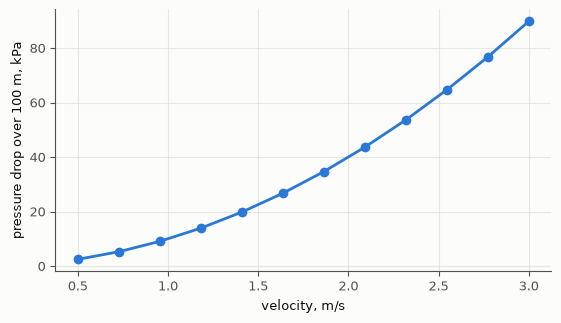

In [3]:
pressure = azoth.batch.hydraulics.darcy_weisbach(
    f=[0.02] * n,
    L=[100.0] * n,
    D=[0.1] * n,
    rho=[998.0] * n,
    v=velocity.tolist(),
    mu=[1.002e-3] * n,
)
print("units:", pressure.units)
print("first value as a quantity:", pressure.quantities("dp")[0])

fig, ax = plt.subplots()
ax.plot(velocity, np.array(pressure.dp) / 1e3, "o-", color=PALETTE[0])
ax.set_xlabel("velocity, m/s")
ax.set_ylabel("pressure drop over 100 m, kPa")
plt.show()
plt.close(fig)

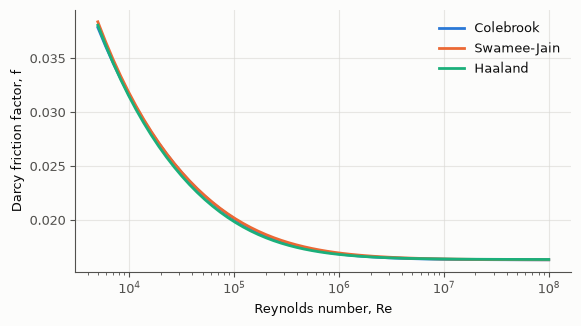

In [4]:
reynolds_sweep = np.logspace(3.7, 8.0, 60)
fig, ax = plt.subplots()
for name, fn, colour in [
    ("Colebrook", azoth.batch.hydraulics.friction_factor_colebrook, PALETTE[0]),
    ("Swamee-Jain", azoth.batch.hydraulics.friction_factor_swamee_jain, PALETTE[1]),
    ("Haaland", azoth.batch.hydraulics.friction_factor_haaland, PALETTE[2]),
]:
    result = fn(re=reynolds_sweep.tolist(), relative_roughness=[4.5e-4] * len(reynolds_sweep))
    ax.plot(reynolds_sweep, list(result.f), color=colour, label=name)
ax.set_xscale("log")
ax.set_xlabel("Reynolds number, Re")
ax.set_ylabel("Darcy friction factor, f")
ax.legend(frameon=False)
plt.show()
plt.close(fig)

## A compressibility sweep

There is no batch flash, but the cubic itself is batchable. `pr_alpha_ab` turns reduced
temperature and pressure into the cubic's `A` and `B`, and `pr_z_factor` returns the admissible
roots and which structure they came from.

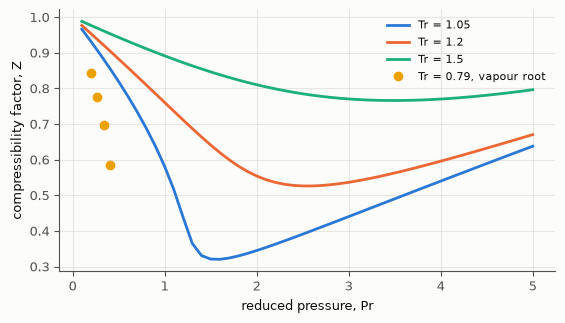

In [5]:
methane = azoth.eos.component("methane")
Tc = methane.Tc.to("K").magnitude
Pc = methane.Pc.to("Pa").magnitude
kappa = float(azoth.batch.eos.pr_kappa(omega=[methane.omega]).kappa[0])

reduced_pressure = np.linspace(0.1, 5.0, 50)
fig, ax = plt.subplots()
for reduced_temperature, colour in [(1.05, PALETTE[0]), (1.2, PALETTE[1]), (1.5, PALETTE[2])]:
    alpha = azoth.batch.eos.pr_alpha_ab(
        kappa=[kappa] * len(reduced_pressure),
        Tr=[reduced_temperature] * len(reduced_pressure),
        Pr=reduced_pressure.tolist(),
    )
    z = azoth.batch.eos.pr_z_factor(
        a_reduced=list(alpha.a_reduced), b_reduced=list(alpha.b_reduced)
    )
    ax.plot(reduced_pressure, list(z.z_max), color=colour, label=f"Tr = {reduced_temperature}")

subcritical = np.linspace(0.2, 1.5, 20)
alpha = azoth.batch.eos.pr_alpha_ab(
    kappa=[kappa] * len(subcritical), Tr=[0.79] * len(subcritical), Pr=subcritical.tolist()
)
z = azoth.batch.eos.pr_z_factor(a_reduced=list(alpha.a_reduced), b_reduced=list(alpha.b_reduced))
three = [i for i, structure in enumerate(z.root_structure) if str(structure) == "three_roots"]
ax.plot(
    [subcritical[i] for i in three],
    [z.z_max[i] for i in three],
    "o",
    color=PALETTE[3],
    label="Tr = 0.79, vapour root",
)
ax.set_xlabel("reduced pressure, Pr")
ax.set_ylabel("compressibility factor, Z")
ax.legend(frameon=False, fontsize=8)
plt.show()
plt.close(fig)

## A conduction sweep

`batch.thermal` is the same construction over a temperature difference in kelvin (an interval,
so no offset is possible).

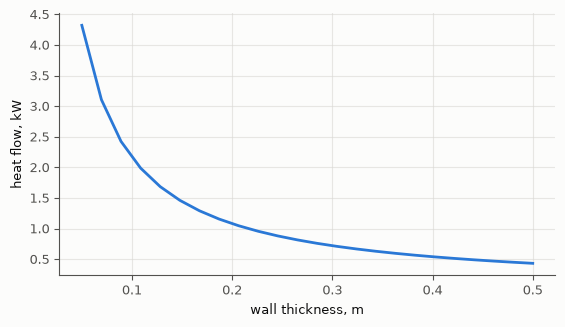

In [6]:
thickness = np.linspace(0.05, 0.5, 24)
heat = azoth.batch.thermal.conduction_plane_wall(
    k=[0.6] * len(thickness),
    A=[12.0] * len(thickness),
    dT=[30.0] * len(thickness),
    L=thickness.tolist(),
)
fig, ax = plt.subplots()
ax.plot(thickness, np.array(heat.q) / 1e3, color=PALETTE[0])
ax.set_xlabel("wall thickness, m")
ax.set_ylabel("heat flow, kW")
plt.show()
plt.close(fig)

## A gas standard over several blends

`azoth.standards` is imported explicitly: `import azoth` does not bind it. ISO 6976 takes
components, mole fractions and the two reference temperatures.

In [7]:
blends = {
    "lean": (["methane", "ethane", "propane"], [0.90, 0.05, 0.05]),
    "nitrogen-rich": (["methane", "ethane", "nitrogen"], [0.85, 0.10, 0.05]),
    "CO2-rich": (["methane", "ethane", "propane", "co2"], [0.80, 0.10, 0.05, 0.05]),
}

rows = []
for name, (components, fractions) in blends.items():
    result = azoth.standards.iso6976(components, fractions, q(288.15, "K"), q(298.15, "K"))
    rows.append(
        {
            "blend": name,
            "superior (MJ/mol)": result.superior_calorific_value.to("MJ/mol").magnitude,
            "inferior (MJ/mol)": result.inferior_calorific_value.to("MJ/mol").magnitude,
            "density (kg/m3)": result.density_real.magnitude,
        }
    )

table = pd.DataFrame(rows)
table

,blend,superior (MJ/mol),inferior (MJ/mol),density (kg/m3)
0,lean,0.990560,0.895927,0.769524
1,nitrogen-rich,0.913104,0.825074,0.764900
2,CO2-rich,0.979531,0.887099,0.858919


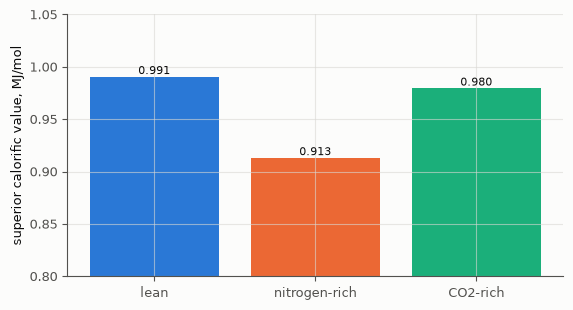

In [8]:
fig, ax = plt.subplots()
ax.bar(table["blend"], table["superior (MJ/mol)"], color=PALETTE[: len(table)])
for index, value in enumerate(table["superior (MJ/mol)"]):
    ax.text(index, value, f"{value:.3f}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("superior calorific value, MJ/mol")
ax.set_ylim(0.8, 1.05)
plt.show()
plt.close(fig)

## What the batch API gives up

- **Unit checking.** `d=[50.0]` for `orifice_flow` means 50 mm; the canonical unit is the
  spec's, not the caller's.
- **The flash.** There is no batch `pt_flash`; a composition sweep has to loop the scalar call.
- **Nothing else.** The batch functions call the same kernels as the scalar API, so the
  cross-language claim is unchanged.

## Next

- [The batch API](https://patrickmockridge.github.io/azoth/manual/index.html#the-batch-api)
  in the book's front matter.
- [Python scripting and Jupyter](https://patrickmockridge.github.io/azoth/manual/using/python.html).